# Discrete-Event Monte Carlo Simulation Engine and Empirical Metrics

In [1]:
import sys
import os
from pathlib import Path
import time

current = Path.cwd().resolve()
while current != current.parent:
    if (current / "requirements.txt").exists():
        project_root = current
        break
    current = current.parent
else:
    project_root = Path.cwd().resolve()

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

from src.models.analytical import (
    DEFAULT_BLOCKS,
    HOURS_PER_YEAR,
    evaluate_scenario_1,
    evaluate_scenario_2,
    evaluate_scenario_3,
)
from src.simulation.monte_carlo import (
    DEFAULT_SEED,
    DEFAULT_NUM_REPLICAS,
    DEFAULT_HORIZON_HOURS,
    SimulationConfig,
    SimulationMetrics,
    ScenarioSimulationResult,
    EmpiricalDistributionSummary,
    simulate_component_renewal,
    merge_outage_intervals,
    intersect_two_interval_lists,
    get_scenario_rates,
    run_monte_carlo_simulation,
    run_all_scenarios_simulation,
    compute_simulation_metrics,
    export_simulation_metrics_to_csv,
    compute_convergence_series,
    compute_running_statistics,
    compute_empirical_distribution_summary,
)
from src.visualization.plot_monte_carlo import (
    plot_monte_carlo_convergence,
    plot_downtime_histograms,
    plot_simulation_subsystem_breakdown,
    generate_all_monte_carlo_diagrams,
)

figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
pd.set_option("display.float_format", lambda x: f"{x:.6f}")
print("Stochastic Monte Carlo Simulation Environment initialized successfully.")
print(f"Project root: {project_root}")
print(f"NumPy seed: {DEFAULT_SEED} | Replicas per scenario: {DEFAULT_NUM_REPLICAS:,} | Horizon: {DEFAULT_HORIZON_HOURS:.1f} hours/year")

Stochastic Monte Carlo Simulation Environment initialized successfully.
Project root: /home/xavier/dev/system-reliability-engineering
NumPy seed: 2026 | Replicas per scenario: 10,000 | Horizon: 8760.0 hours/year


## 1. System Parameterization and Stochastic Transition Rates

In [2]:
param_rows = []
for code, b in DEFAULT_BLOCKS.items():
    mu = 1.0 / b.mttr_hours
    lam = b.lambda_base
    expected_failures_annual = lam * HOURS_PER_YEAR
    param_rows.append({
        "Block": b.code,
        "Subsystem Name": b.name,
        "Architectural Tier": b.tier,
        "Baseline SLA ($A_i$)": f"{b.availability_base * 100:.2f}%",
        "Multi-AZ SLA ($A_{i,red}$)": f"{b.availability_redundant * 100:.4f}%" if b.availability_redundant else "—",
        "MTTR (h)": b.mttr_hours,
        r"Repair Rate $\mu$ (h$^{-1}$)": mu,
        r"Failure Rate $\lambda$ ($10^{-3}$ h$^{-1}$)": lam * 1e3,
        "MTBF (hours)": b.mtbf_hours_base,
        "Expected Failures/Year": expected_failures_annual,
    })

df_params = pd.DataFrame(param_rows)
display(df_params)

,Block,Subsystem Name,Architectural Tier,Baseline SLA ($A_i$),"Multi-AZ SLA ($A_{i,red}$)",MTTR (h),Repair Rate $\mu$ (h$^{-1}$),Failure Rate $\lambda$ ($10^{-3}$ h$^{-1}$),MTBF (hours),Expected Failures/Year
0,LB,Load Balancer,Ingress & Routing,99.99%,99.9900%,0.250000,4.000000,0.400040,2499.750000,3.504350
1,App,Application Server,Business Logic & Auth,99.50%,99.9900%,0.500000,2.000000,10.050251,99.500000,88.040201
2,DB,Transactional Database,Data Persistence,99.50%,99.9500%,1.000000,1.000000,5.025126,199.000000,44.020101
3,PGW,Payment Gateway,External Settlement Network,99.95%,100.0000%,0.500000,2.000000,1.000500,999.500000,8.764382


## 2. Scenario 1: Pure Series Architecture Simulation

In [3]:
config = SimulationConfig(
    seed=DEFAULT_SEED,
    num_replicas=DEFAULT_NUM_REPLICAS,
    horizon_hours=DEFAULT_HORIZON_HOURS,
    confidence_level=0.95,
)

print(f"Executing Scenario 1 Monte Carlo simulation (N = {config.num_replicas:,} replicas)...")
sim_s1 = run_monte_carlo_simulation(scenario_id=1, config=config)

print(f"Simulation completed in {sim_s1.execution_time_seconds:.3f} seconds.")

print(f"\nTheoretical Availability (A_base): {sim_s1.metrics.theoretical_availability * 100:.4f}%")
print(f"Simulated Availability (A_hat): {sim_s1.metrics.mean_availability * 100:.4f}%")
print(f"Bilateral 95% Confidence Interval: [{sim_s1.metrics.ci_availability_lower * 100:.4f}%, {sim_s1.metrics.ci_availability_upper * 100:.4f}%]")
print(f"Availability Relative Error: {sim_s1.metrics.relative_error_availability_pct:.5f}%")
print(f"Theoretical Annual Downtime (D_base): {sim_s1.metrics.theoretical_downtime_hours:.2f} hours/year")
print(f"Simulated Annual Downtime (D_hat): {sim_s1.metrics.mean_downtime_hours:.2f} hours/year")
print(f"Downtime 95% Confidence Interval: [{sim_s1.metrics.ci_downtime_lower_hours:.2f} h, {sim_s1.metrics.ci_downtime_upper_hours:.2f} h]")
print(f"Mean Failure Events per Year: {sim_s1.metrics.mean_failures_per_year:.1f} events/year")


# Display sample of first 10 simulated years
df_s1_sample = sim_s1.to_dataframe().head(10)
display(df_s1_sample)

Executing Scenario 1 Monte Carlo simulation (N = 10,000 replicas)...
Simulation completed in 1.812 seconds.

Theoretical Availability (A_base): 98.9431%
Simulated Availability (A_hat): 98.9425%
Bilateral 95% Confidence Interval: [98.9399%, 98.9451%]
Availability Relative Error: 0.00064%
Theoretical Annual Downtime (D_base): 92.58 hours/year
Simulated Annual Downtime (D_hat): 92.64 hours/year
Downtime 95% Confidence Interval: [92.41 h, 92.87 h]
Mean Failure Events per Year: 142.9 events/year


,replica_id,availability,downtime_hours,operational_hours,failure_count,downtime_LB_hours,downtime_App_hours,downtime_DB_hours,downtime_PGW_hours
0,1,0.989379,93.037267,8666.962733,129,0.759735,45.553942,41.242802,5.480788
1,2,0.992213,68.215231,8691.784769,121,1.266041,37.962564,28.359138,0.793688
2,3,0.989749,89.796437,8670.203563,119,0.087748,35.974771,48.691303,5.126758
3,4,0.988959,96.715644,8663.284356,132,0.356575,33.722320,58.644229,4.170502
4,5,0.991641,73.224385,8686.775615,136,1.216310,39.870208,27.163596,4.982447
5,6,0.988407,101.554912,8658.445088,148,0.405386,50.211879,45.096867,5.840779
6,7,0.989961,87.944281,8672.055719,152,0.204205,38.469470,42.515859,6.754747
7,8,0.989297,93.755180,8666.244820,149,1.066523,49.739623,36.185506,6.763529
8,9,0.991869,71.226345,8688.773655,122,0.344511,39.315083,28.016549,3.550202
9,10,0.989030,96.095443,8663.904557,155,1.276666,40.535436,51.718774,2.603925


## 3. Scenario 2: Multi-AZ Series-Parallel Architecture Simulation

In [4]:
print(f"Executing Scenario 2 Monte Carlo simulation (N = {config.num_replicas:,} replicas)...")
sim_s2 = run_monte_carlo_simulation(scenario_id=2, config=config)

print(f"Simulation completed in {sim_s2.execution_time_seconds:.3f} seconds.")

print(f"\nTheoretical Availability (A_red): {sim_s2.metrics.theoretical_availability * 100:.4f}%")
print(f"Simulated Availability (A_hat): {sim_s2.metrics.mean_availability * 100:.4f}%")
print(f"Bilateral 95% Confidence Interval: [{sim_s2.metrics.ci_availability_lower * 100:.4f}%, {sim_s2.metrics.ci_availability_upper * 100:.4f}%]")
print(f"Availability Relative Error: {sim_s2.metrics.relative_error_availability_pct:.5f}%")
print(f"Theoretical Annual Downtime (D_red): {sim_s2.metrics.theoretical_downtime_hours:.2f} hours/year")
print(f"Simulated Annual Downtime (D_hat): {sim_s2.metrics.mean_downtime_hours:.2f} hours/year")
print(f"Downtime 95% Confidence Interval: [{sim_s2.metrics.ci_downtime_lower_hours:.2f} h, {sim_s2.metrics.ci_downtime_upper_hours:.2f} h]")
print(f"Mean Failure Events per Year: {sim_s2.metrics.mean_failures_per_year:.1f} events/year")


# Comparative gain vs Scenario 1
d_saved = sim_s1.metrics.mean_downtime_hours - sim_s2.metrics.mean_downtime_hours
pct_reduced = (d_saved / sim_s1.metrics.mean_downtime_hours) * 100.0
print(f"Simulated Downtime Saved (S2 vs S1): {d_saved:.2f} hours/year ({pct_reduced:.2f}% reduction)")

df_s2_sample = sim_s2.to_dataframe().head(10)
display(df_s2_sample)

Executing Scenario 2 Monte Carlo simulation (N = 10,000 replicas)...
Simulation completed in 0.286 seconds.

Theoretical Availability (A_red): 99.8800%
Simulated Availability (A_hat): 99.8802%
Bilateral 95% Confidence Interval: [99.8794%, 99.8811%]
Availability Relative Error: 0.00019%
Theoretical Annual Downtime (D_red): 10.51 hours/year
Simulated Annual Downtime (D_hat): 10.49 hours/year
Downtime 95% Confidence Interval: [10.42 h, 10.56 h]
Mean Failure Events per Year: 18.4 events/year
Simulated Downtime Saved (S2 vs S1): 82.15 hours/year (88.68% reduction)


,replica_id,availability,downtime_hours,operational_hours,failure_count,downtime_LB_hours,downtime_App_hours,downtime_DB_hours,downtime_PGW_hours
0,1,0.999173,7.240974,8752.759026,16,0.759735,0.844469,2.982146,2.654624
1,2,0.999181,7.171781,8752.828219,13,0.040214,0.218253,4.794595,2.118718
2,3,0.997963,17.848025,8742.151975,18,1.041662,0.398569,1.575416,14.832377
3,4,0.999066,8.180046,8751.819954,13,0.033380,1.267725,6.109972,0.768969
4,5,0.998414,13.894231,8746.105769,20,1.477401,1.702088,5.484130,5.230612
5,6,0.998896,9.671384,8750.328616,22,1.850444,0.277486,4.091859,3.451595
6,7,0.998116,16.502672,8743.497328,23,0.947116,0.000000,9.045906,6.509650
7,8,0.998195,15.812162,8744.187838,22,1.453390,0.756374,6.237271,7.365126
8,9,0.999027,8.521364,8751.478636,13,0.954590,0.000000,1.778273,5.788500
9,10,0.999088,7.985163,8752.014837,20,0.495887,0.605836,0.902499,5.980941


## 4. Scenario 3: Multi-Gateway Expansion Simulation

In [5]:
print(f"Executing Scenario 3 Monte Carlo simulation (N = {config.num_replicas:,} replicas)...")
sim_s3 = run_monte_carlo_simulation(scenario_id=3, config=config)

print(f"Simulation completed in {sim_s3.execution_time_seconds:.3f} seconds.")

print(f"\nTheoretical Availability (A_scen3): {sim_s3.metrics.theoretical_availability * 100:.4f}%")
print(f"Simulated Availability (A_hat): {sim_s3.metrics.mean_availability * 100:.4f}%")
print(f"Bilateral 95% Confidence Interval: [{sim_s3.metrics.ci_availability_lower * 100:.4f}%, {sim_s3.metrics.ci_availability_upper * 100:.4f}%]")
print(f"Availability Relative Error: {sim_s3.metrics.relative_error_availability_pct:.5f}%")
print(f"Theoretical Annual Downtime (D_scen3): {sim_s3.metrics.theoretical_downtime_hours:.2f} hours/year")
print(f"Simulated Annual Downtime (D_hat): {sim_s3.metrics.mean_downtime_hours:.2f} hours/year")
print(f"Downtime 95% Confidence Interval: [{sim_s3.metrics.ci_downtime_lower_hours:.2f} h, {sim_s3.metrics.ci_downtime_upper_hours:.2f} h]")


df_s3_sample = sim_s3.to_dataframe().head(10)
display(df_s3_sample)

Executing Scenario 3 Monte Carlo simulation (N = 10,000 replicas)...
Simulation completed in 0.181 seconds.

Theoretical Availability (A_scen3): 99.9300%
Simulated Availability (A_hat): 99.9293%
Bilateral 95% Confidence Interval: [99.9286%, 99.9300%]
Availability Relative Error: 0.00066%
Theoretical Annual Downtime (D_scen3): 6.13 hours/year
Simulated Annual Downtime (D_hat): 6.19 hours/year
Downtime 95% Confidence Interval: [6.13 h, 6.25 h]


,replica_id,availability,downtime_hours,operational_hours,failure_count,downtime_LB_hours,downtime_App_hours,downtime_DB_hours,downtime_PGW_hours
0,1,0.999476,4.586350,8755.413650,9,0.759735,0.844469,2.982146,0.000000
1,2,0.999570,3.767096,8756.232904,7,1.441203,0.292255,2.033638,0.000000
2,3,0.998434,13.714167,8746.285833,12,1.587680,1.151937,10.974550,0.000000
3,4,0.999754,2.151389,8757.848611,7,0.177404,0.398569,1.575416,0.000000
4,5,0.999320,5.954971,8754.045029,5,0.320444,4.283818,1.350709,0.000000
5,6,0.998814,10.391824,8749.608176,13,1.592872,2.688980,6.109972,0.000000
6,7,0.999471,4.631055,8755.368945,10,2.475697,0.000000,2.155358,0.000000
7,8,0.999420,5.080403,8754.919597,9,1.073273,2.068093,1.939037,0.000000
8,9,0.999490,4.469427,8755.530573,6,1.438956,0.202640,2.827832,0.000000
9,10,0.999677,2.832228,8757.167772,11,1.079751,0.000000,1.752477,0.000000


## 5. Statistical Estimators, Empirical Metrics, and Acceptance Validation

In [6]:
all_sim_results = {1: sim_s1, 2: sim_s2, 3: sim_s3}

summary_rows = []
for s_id, s_res in all_sim_results.items():
    m = s_res.metrics
    summary_rows.append({
        "Scenario": f"Scenario {s_id}",
        "Name": m.scenario_name,
        "Theoretical A (%)": m.theoretical_availability * 100.0,
        "Simulated A_hat (%)": m.mean_availability * 100.0,
        "A_hat 95% CI": f"[{m.ci_availability_lower * 100:.4f}%, {m.ci_availability_upper * 100:.4f}%]",
        "Theoretical D (h/yr)": m.theoretical_downtime_hours,
        "Simulated D_hat (h/yr)": m.mean_downtime_hours,
        "D_hat 95% CI (h)": f"[{m.ci_downtime_lower_hours:.2f}, {m.ci_downtime_upper_hours:.2f}]",
        "A Relative Error (%)": m.relative_error_availability_pct,
        "Status (<0.05%)": "PASSED" if m.relative_error_availability_pct < 0.05 else "FAILED",
        "Execution Time (s)": s_res.execution_time_seconds,
    })

df_summary = pd.DataFrame(summary_rows)
display(df_summary)

csv_path = export_simulation_metrics_to_csv(all_sim_results)
print(f"\nAutomated CSV summary successfully generated at: {csv_path}")

df_csv_check = pd.read_csv(csv_path)
print(f"Verified {len(df_csv_check)} scenario records written to {csv_path.name}.")

,Scenario,Name,Theoretical A (%),Simulated A_hat (%),A_hat 95% CI,Theoretical D (h/yr),Simulated D_hat (h/yr),D_hat 95% CI (h),A Relative Error (%),Status (<0.05%),Execution Time (s)
0,Scenario 1,Scenario 1 (Baseline Series),98.943103,98.942474,"[98.9399%, 98.9451%]",92.584138,92.639306,"[92.41, 92.87]",0.000637,PASSED,1.811888
1,Scenario 2,Scenario 2 (Multi-AZ Series-Parallel),99.880046,99.880240,"[99.8794%, 99.8811%]",10.507971,10.490986,"[10.42, 10.56]",0.000194,PASSED,0.286452
2,Scenario 3,Scenario 3 (Multi-Gateway Expansion),99.929986,99.929328,"[99.9286%, 99.9300%]",6.133225,6.190900,"[6.13, 6.25]",0.000659,PASSED,0.180549



Automated CSV summary successfully generated at: /home/xavier/dev/system-reliability-engineering/data/processed/simulation_metrics.csv
Verified 3 scenario records written to simulation_metrics.csv.


## 6. Asymptotic Convergence Analysis 


ASYMPTOTIC CONVERGENCE MILESTONES TABLE (N = 10,000)



,Scenario,Replications (n),Cumulative A_hat (%),Theoretical A (%),95% Margin (+/- %),Relative Error (%),Status (<0.05%)
2,Scenario 1,100,98.939724,98.943103,0.026090,0.003415,PASSED
3,Scenario 1,500,98.951723,98.943103,0.011571,0.008712,PASSED
4,Scenario 1,1000,98.950946,98.943103,0.008464,0.007927,PASSED
6,Scenario 1,5000,98.944124,98.943103,0.003674,0.001031,PASSED
8,Scenario 1,10000,98.942474,98.943103,0.002584,0.000637,PASSED
11,Scenario 2,100,99.881821,99.880046,0.007701,0.001777,PASSED
12,Scenario 2,500,99.880076,99.880046,0.003890,0.000030,PASSED
13,Scenario 2,1000,99.880273,99.880046,0.002656,0.000227,PASSED
15,Scenario 2,5000,99.879790,99.880046,0.001195,0.000256,PASSED
17,Scenario 2,10000,99.880240,99.880046,0.000836,0.000194,PASSED


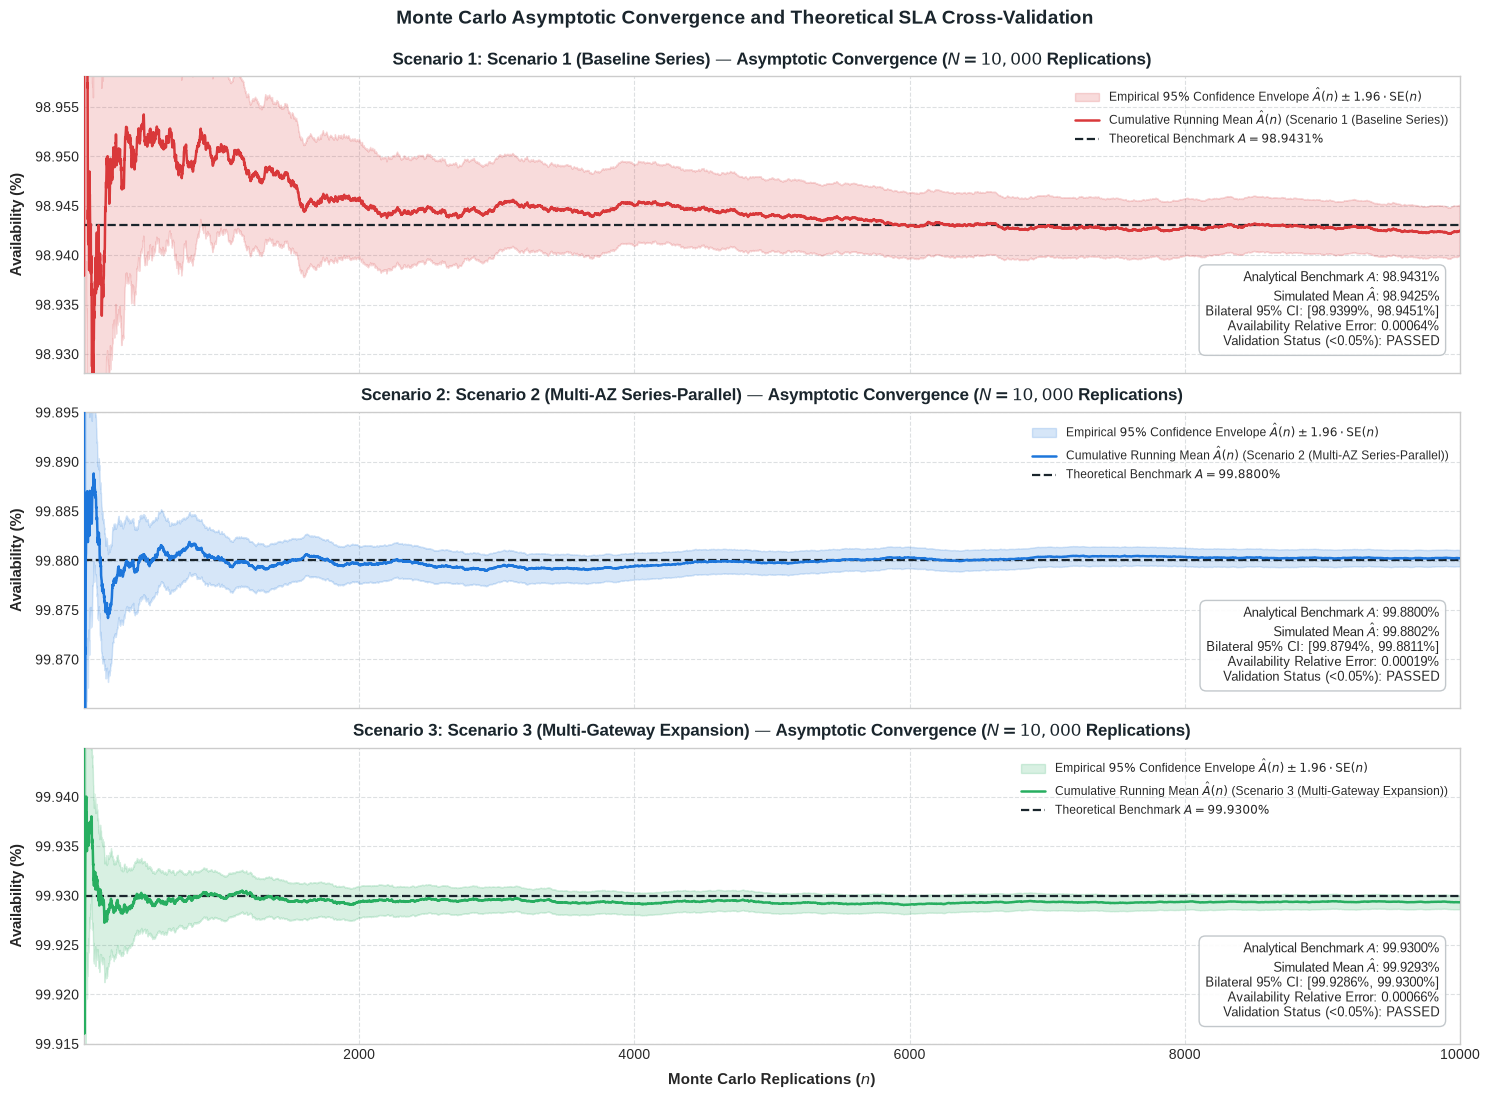

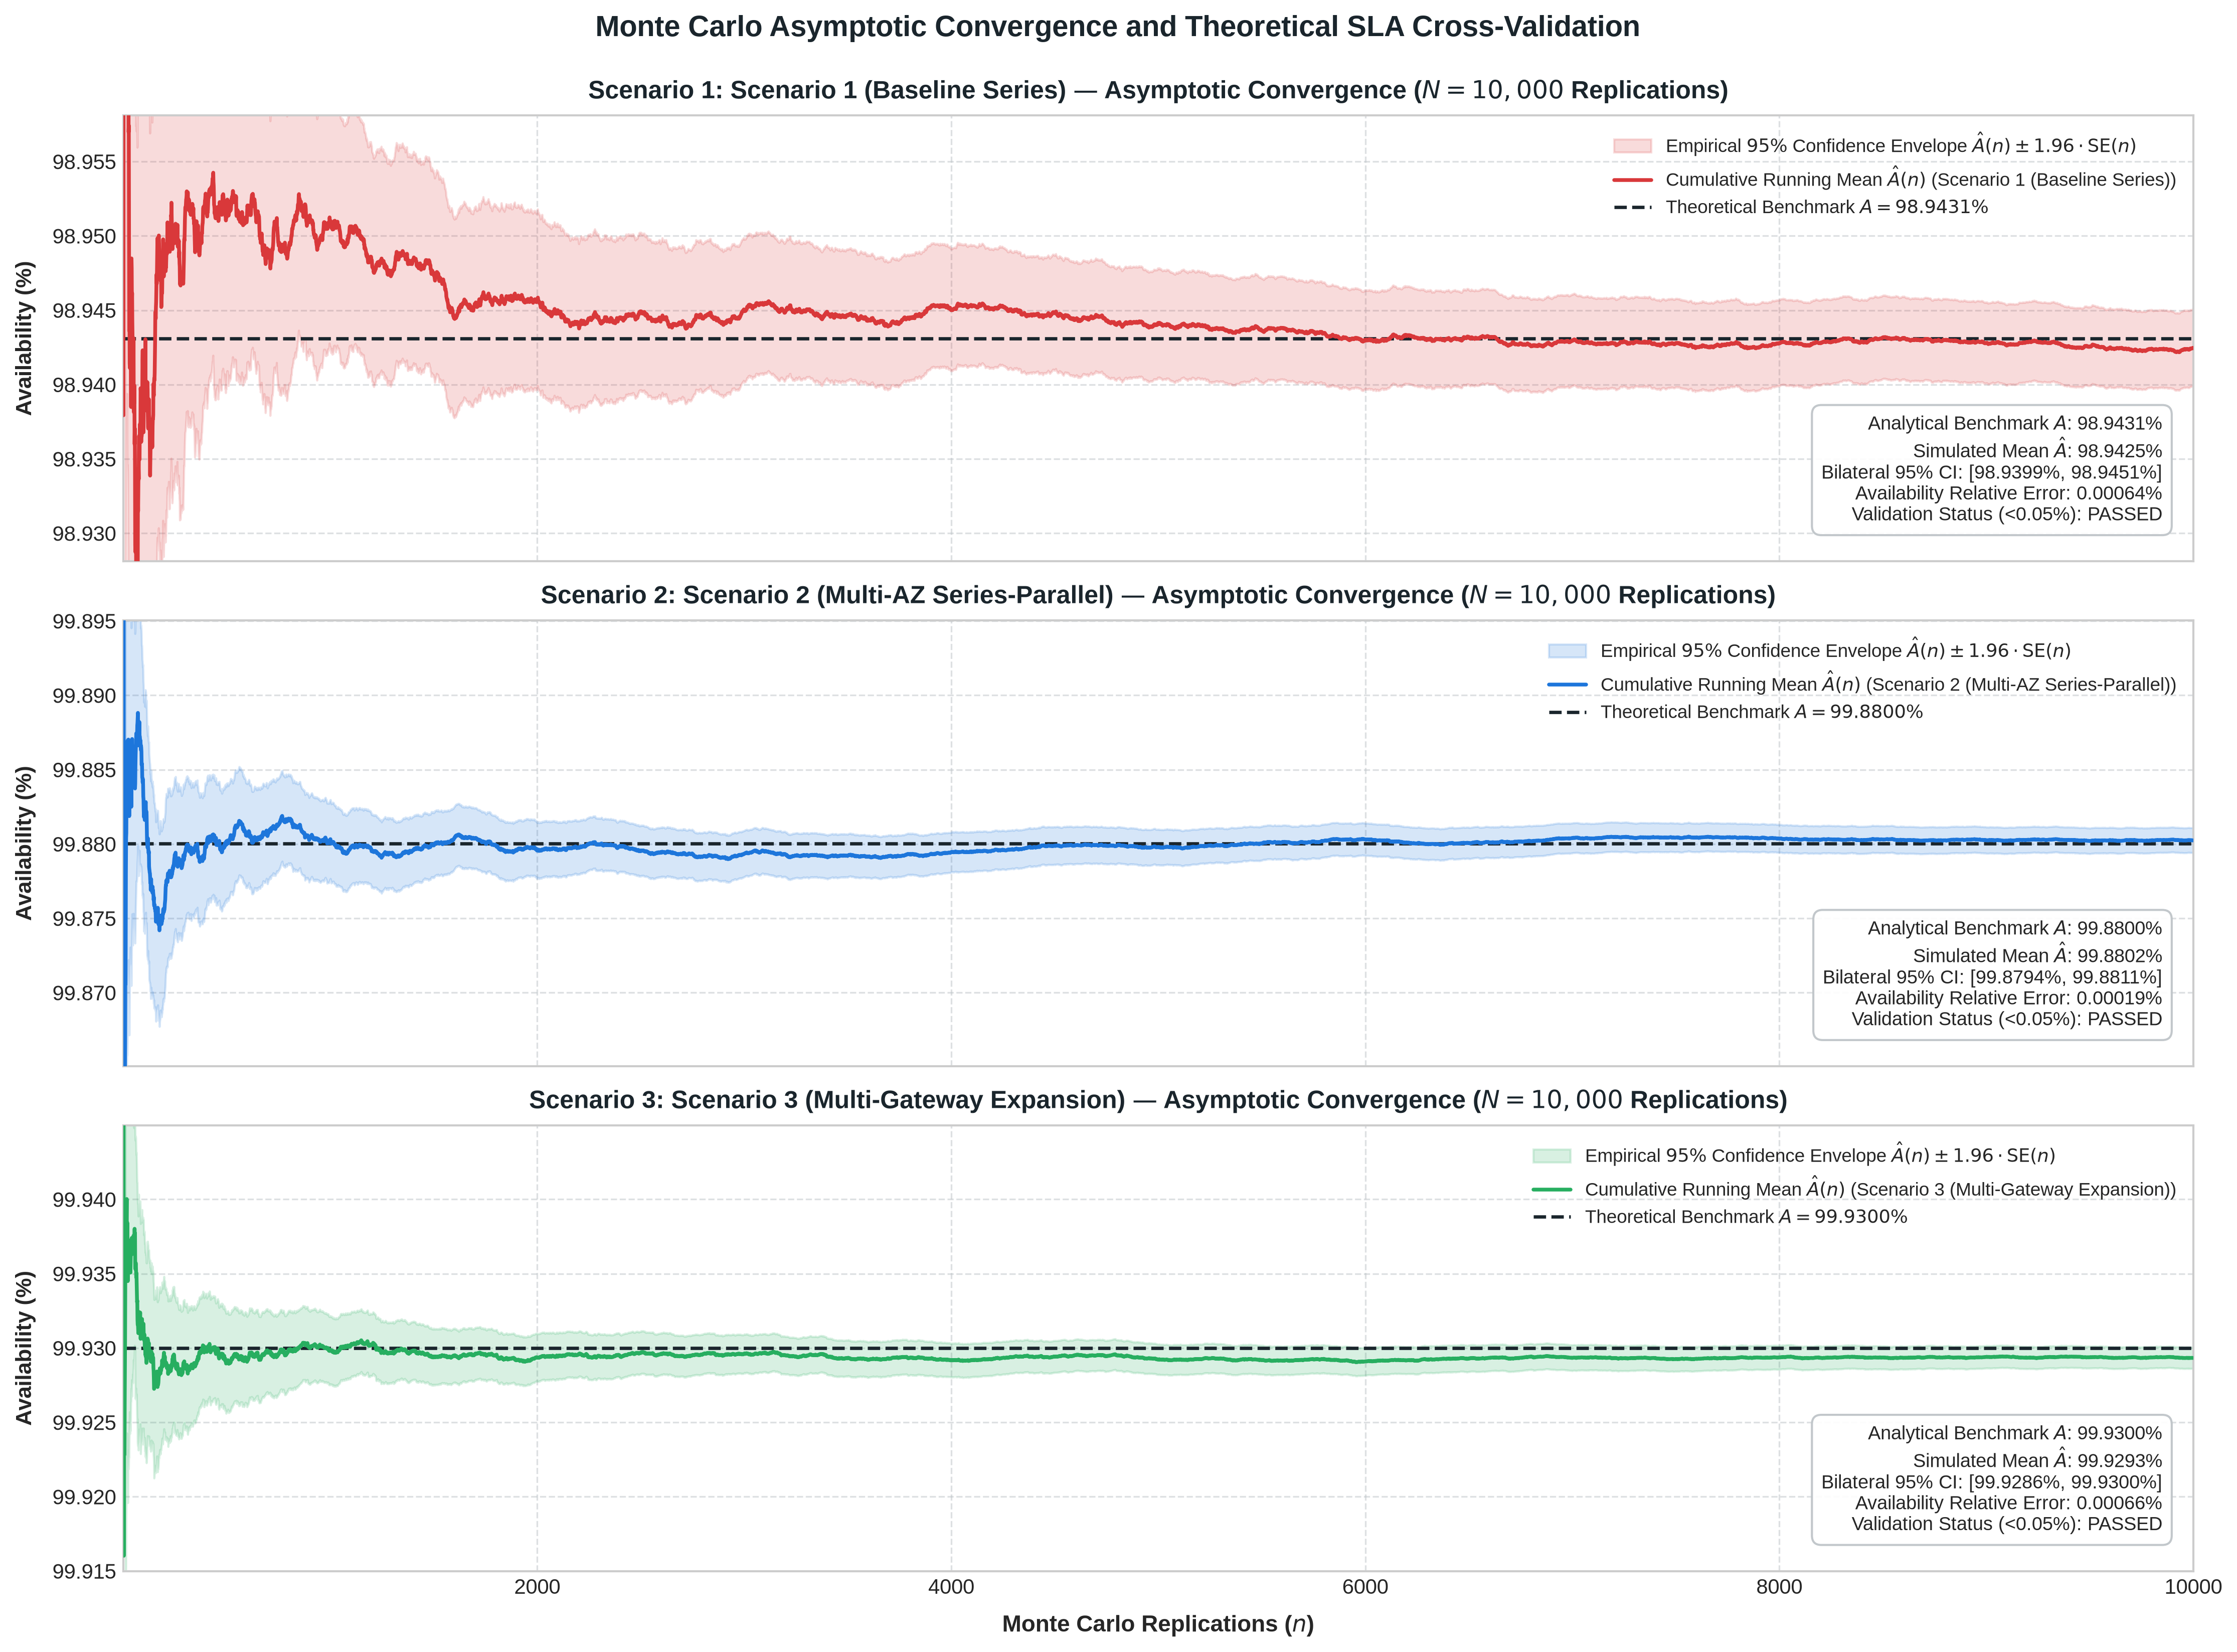

In [7]:
milestone_indices = [10, 50, 100, 500, 1000, 2500, 5000, 7500, 10000]
milestone_rows = []

for s_id, res in all_sim_results.items():
    cum_mean, cum_std, margin = compute_running_statistics(res.availability)
    theo_a = res.metrics.theoretical_availability
    for m in milestone_indices:
        idx = m - 1
        err_pct = abs(cum_mean[idx] - theo_a) / theo_a * 100.0
        milestone_rows.append({
            'Scenario': f'Scenario {s_id}',
            'Replications (n)': m,
            'Cumulative A_hat (%)': cum_mean[idx] * 100.0,
            'Theoretical A (%)': theo_a * 100.0,
            '95% Margin (+/- %)': margin[idx] * 100.0,
            'Relative Error (%)': err_pct,
            'Status (<0.05%)': 'PASSED' if err_pct < 0.05 else 'FAILED',
        })

df_milestones = pd.DataFrame(milestone_rows)
print('\nASYMPTOTIC CONVERGENCE MILESTONES TABLE (N = 10,000)\n')
display(df_milestones[df_milestones['Replications (n)'].isin([100, 500, 1000, 5000, 10000])])

# Generate and export publication convergence curves
fig_conv = plot_monte_carlo_convergence(all_sim_results, output_dir=figures_dir)
plt.show()

conv_img_path = figures_dir / 'monte_carlo_convergence.png'
if conv_img_path.exists():
    display(Image(filename=str(conv_img_path), width=900))


## 7. Empirical Annual Downtime Distribution and SLA Risk Analysis


EMPIRICAL ANNUAL DOWNTIME DISTRIBUTION & SLA RISK METRICS



,Scenario,Name,Analytical D (h/yr),Simulated Mean D (h/yr),Std Dev (h/yr),Median p50 (h/yr),90th %ile (h/yr),95th %ile D_0.95 (h/yr),99th %ile D_0.99 (h/yr),Max Downtime (h/yr),Risk Buffer D_0.95 - D_hat (h),Skewness
0,Scenario 1,Scenario 1 (Baseline Series),92.584138,92.639306,11.549930,92.162634,107.724488,112.209052,121.152444,138.150843,19.569746,0.187403
1,Scenario 2,Scenario 2 (Multi-AZ Series-Parallel),10.507971,10.490986,3.738370,10.115176,15.531915,17.169438,20.852768,29.039937,6.678453,0.578516
2,Scenario 3,Scenario 3 (Multi-Gateway Expansion),6.133225,6.190900,3.203967,5.726017,10.510374,12.071399,15.451717,23.238965,5.880500,0.862683


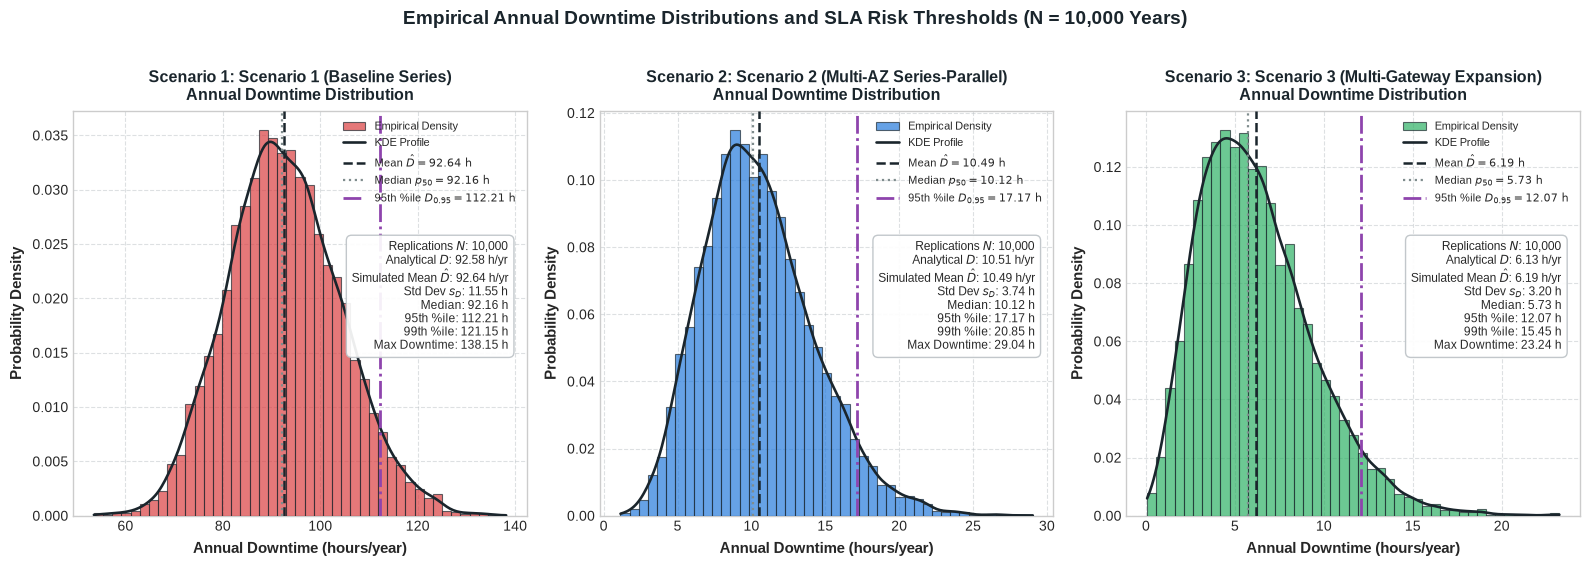

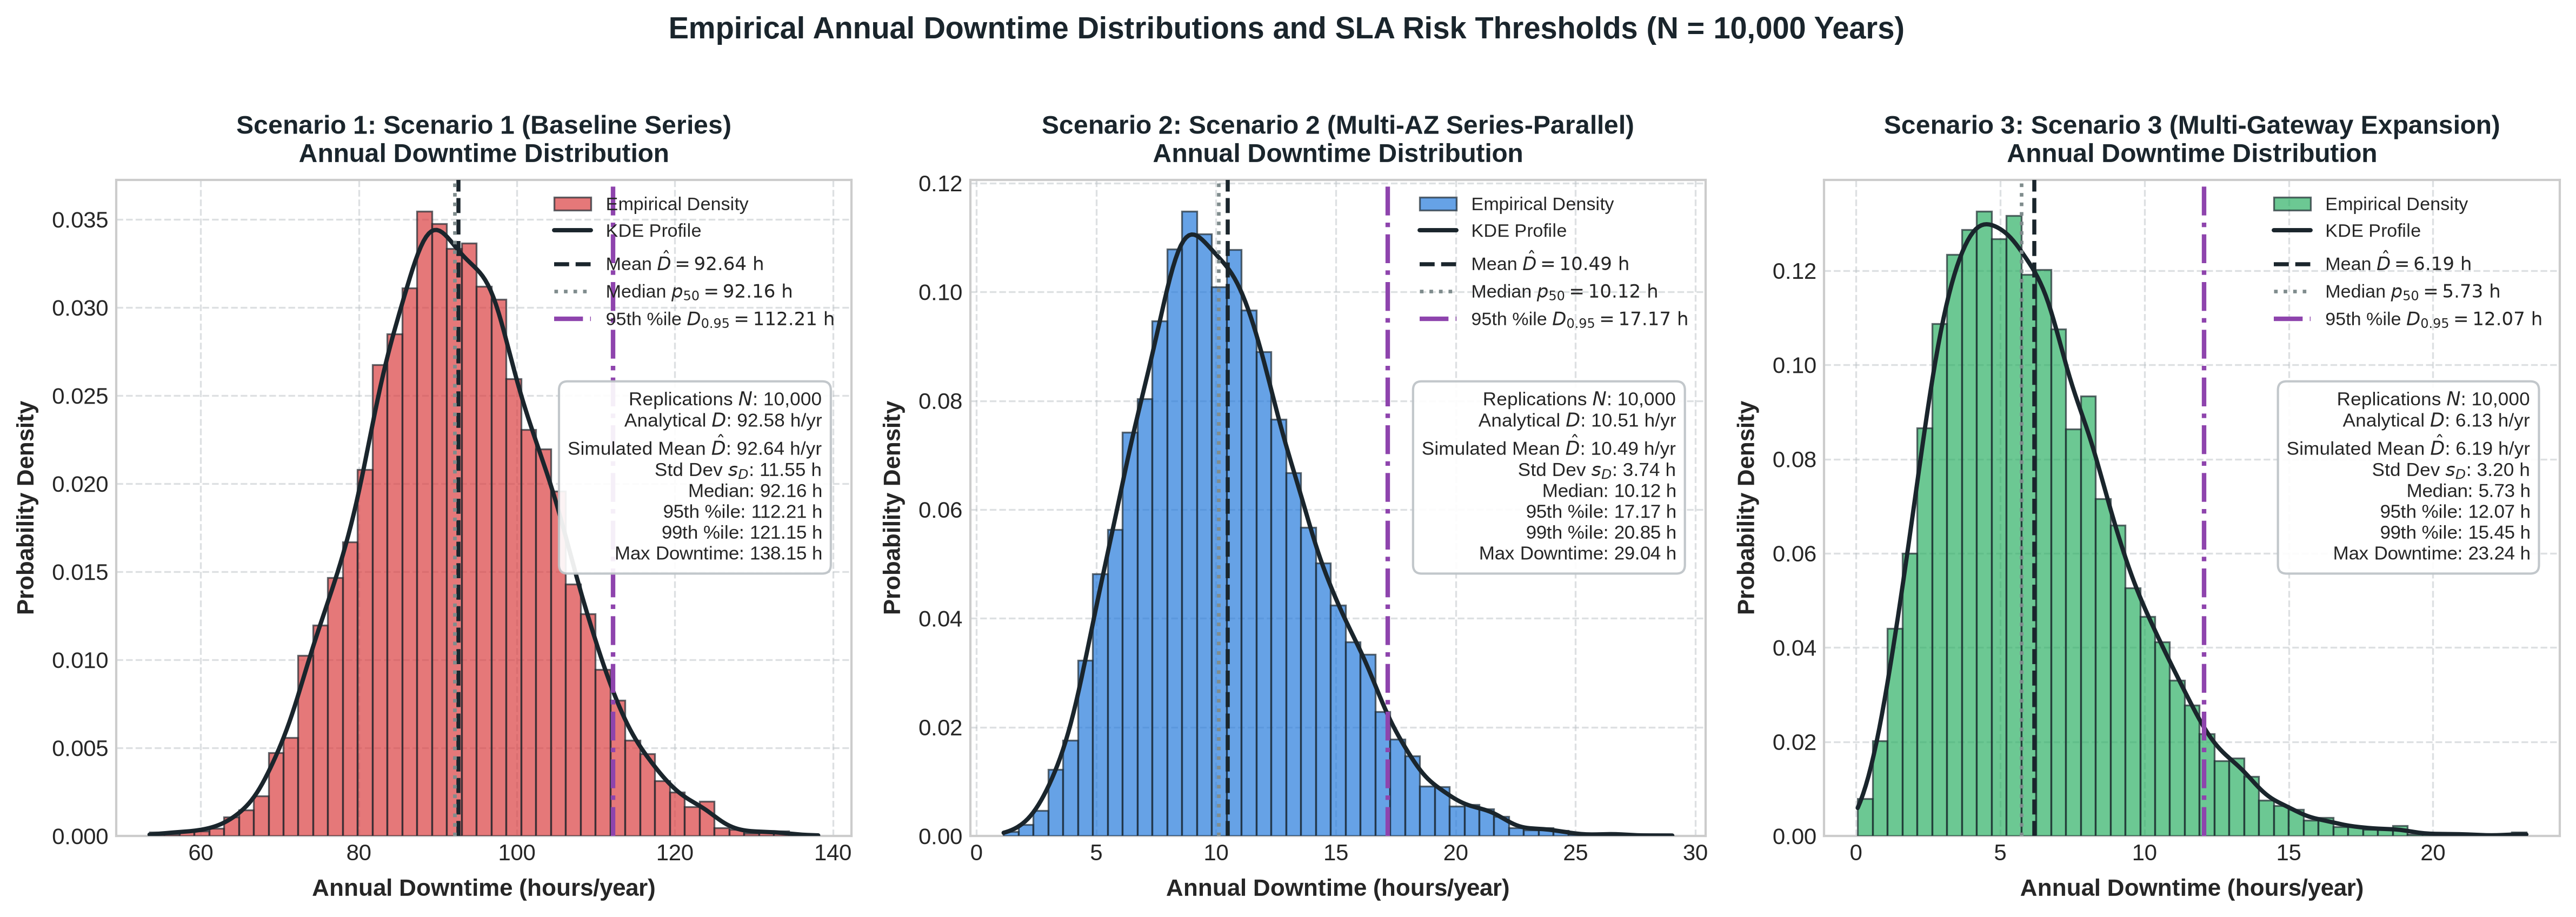

In [8]:
dist_rows = []
for s_id, res in all_sim_results.items():
    summary = compute_empirical_distribution_summary(
        res.downtime_hours,
        scenario_id=s_id,
        scenario_name=res.name,
    )
    m = res.metrics
    dist_rows.append({
        'Scenario': f'Scenario {s_id}',
        'Name': res.name,
        'Analytical D (h/yr)': m.theoretical_downtime_hours,
        'Simulated Mean D (h/yr)': summary.mean,
        'Std Dev (h/yr)': summary.std,
        'Median p50 (h/yr)': summary.median,
        '90th %ile (h/yr)': summary.p90,
        '95th %ile D_0.95 (h/yr)': summary.p95,
        '99th %ile D_0.99 (h/yr)': summary.p99,
        'Max Downtime (h/yr)': summary.max_val,
        'Risk Buffer D_0.95 - D_hat (h)': summary.p95 - summary.mean,
        'Skewness': summary.skewness,
    })

df_dist = pd.DataFrame(dist_rows)
print('\nEMPIRICAL ANNUAL DOWNTIME DISTRIBUTION & SLA RISK METRICS\n')
display(df_dist)

# Generate and export publication downtime histograms with mean and 95th percentile markers
fig_hist = plot_downtime_histograms(all_sim_results, output_dir=figures_dir)
plt.show()

hist_img_path = figures_dir / 'downtime_histogram.png'
if hist_img_path.exists():
    display(Image(filename=str(hist_img_path), width=900))


## 8. Simulated Subsystem Downtime Breakdown and Pareto Validation


SIMULATED VS. ANALYTICAL SUBSYSTEM DOWNTIME (PARETO CROSS-VALIDATION)



,Scenario,Block,Analytical D_i (h/yr),Simulated D_hat_i (h/yr),Simulated Share (%),Abs Difference (h)
0,Scenario 1,LB,0.876000,0.866671,0.935533,0.009329
1,Scenario 1,App,43.800000,43.848922,47.332956,0.048922
2,Scenario 1,DB,43.800000,43.782815,47.261597,0.017185
3,Scenario 1,PGW,4.380000,4.411656,4.762186,0.031656
4,Scenario 2,LB,0.876000,0.881523,8.402666,0.005523
5,Scenario 2,App,0.876000,0.873483,8.326035,0.002517
6,Scenario 2,DB,4.380000,4.354744,41.509386,0.025256
7,Scenario 2,PGW,4.380000,4.385504,41.802593,0.005504
8,Scenario 3,LB,0.876000,0.877615,14.175884,0.001615
9,Scenario 3,App,0.876000,0.882431,14.253687,0.006431


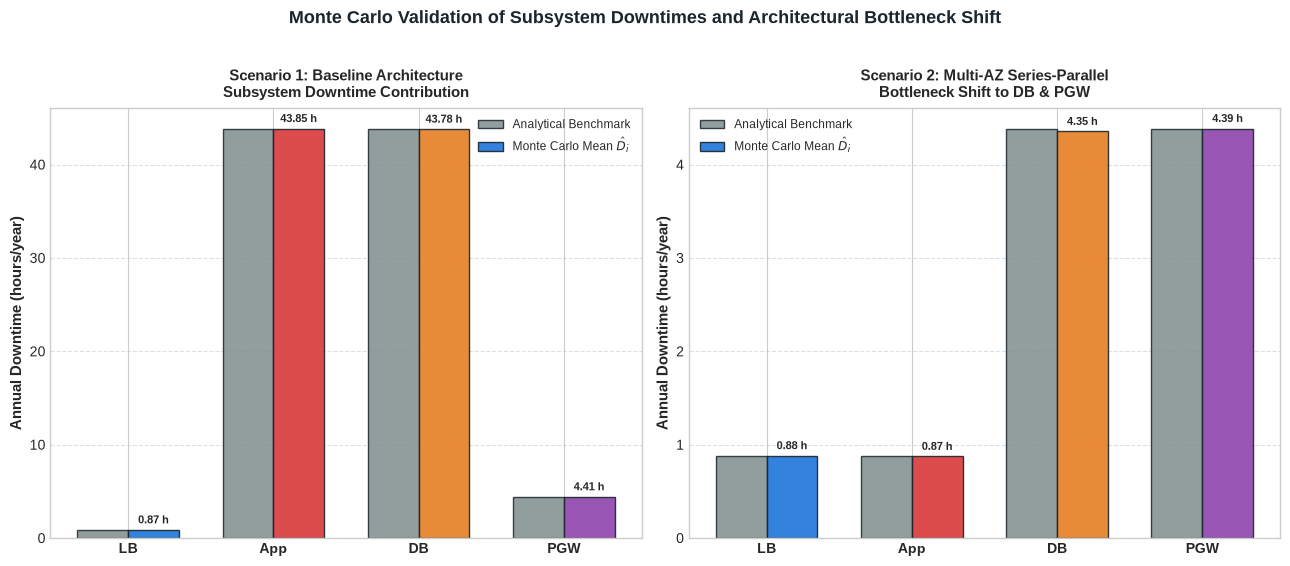

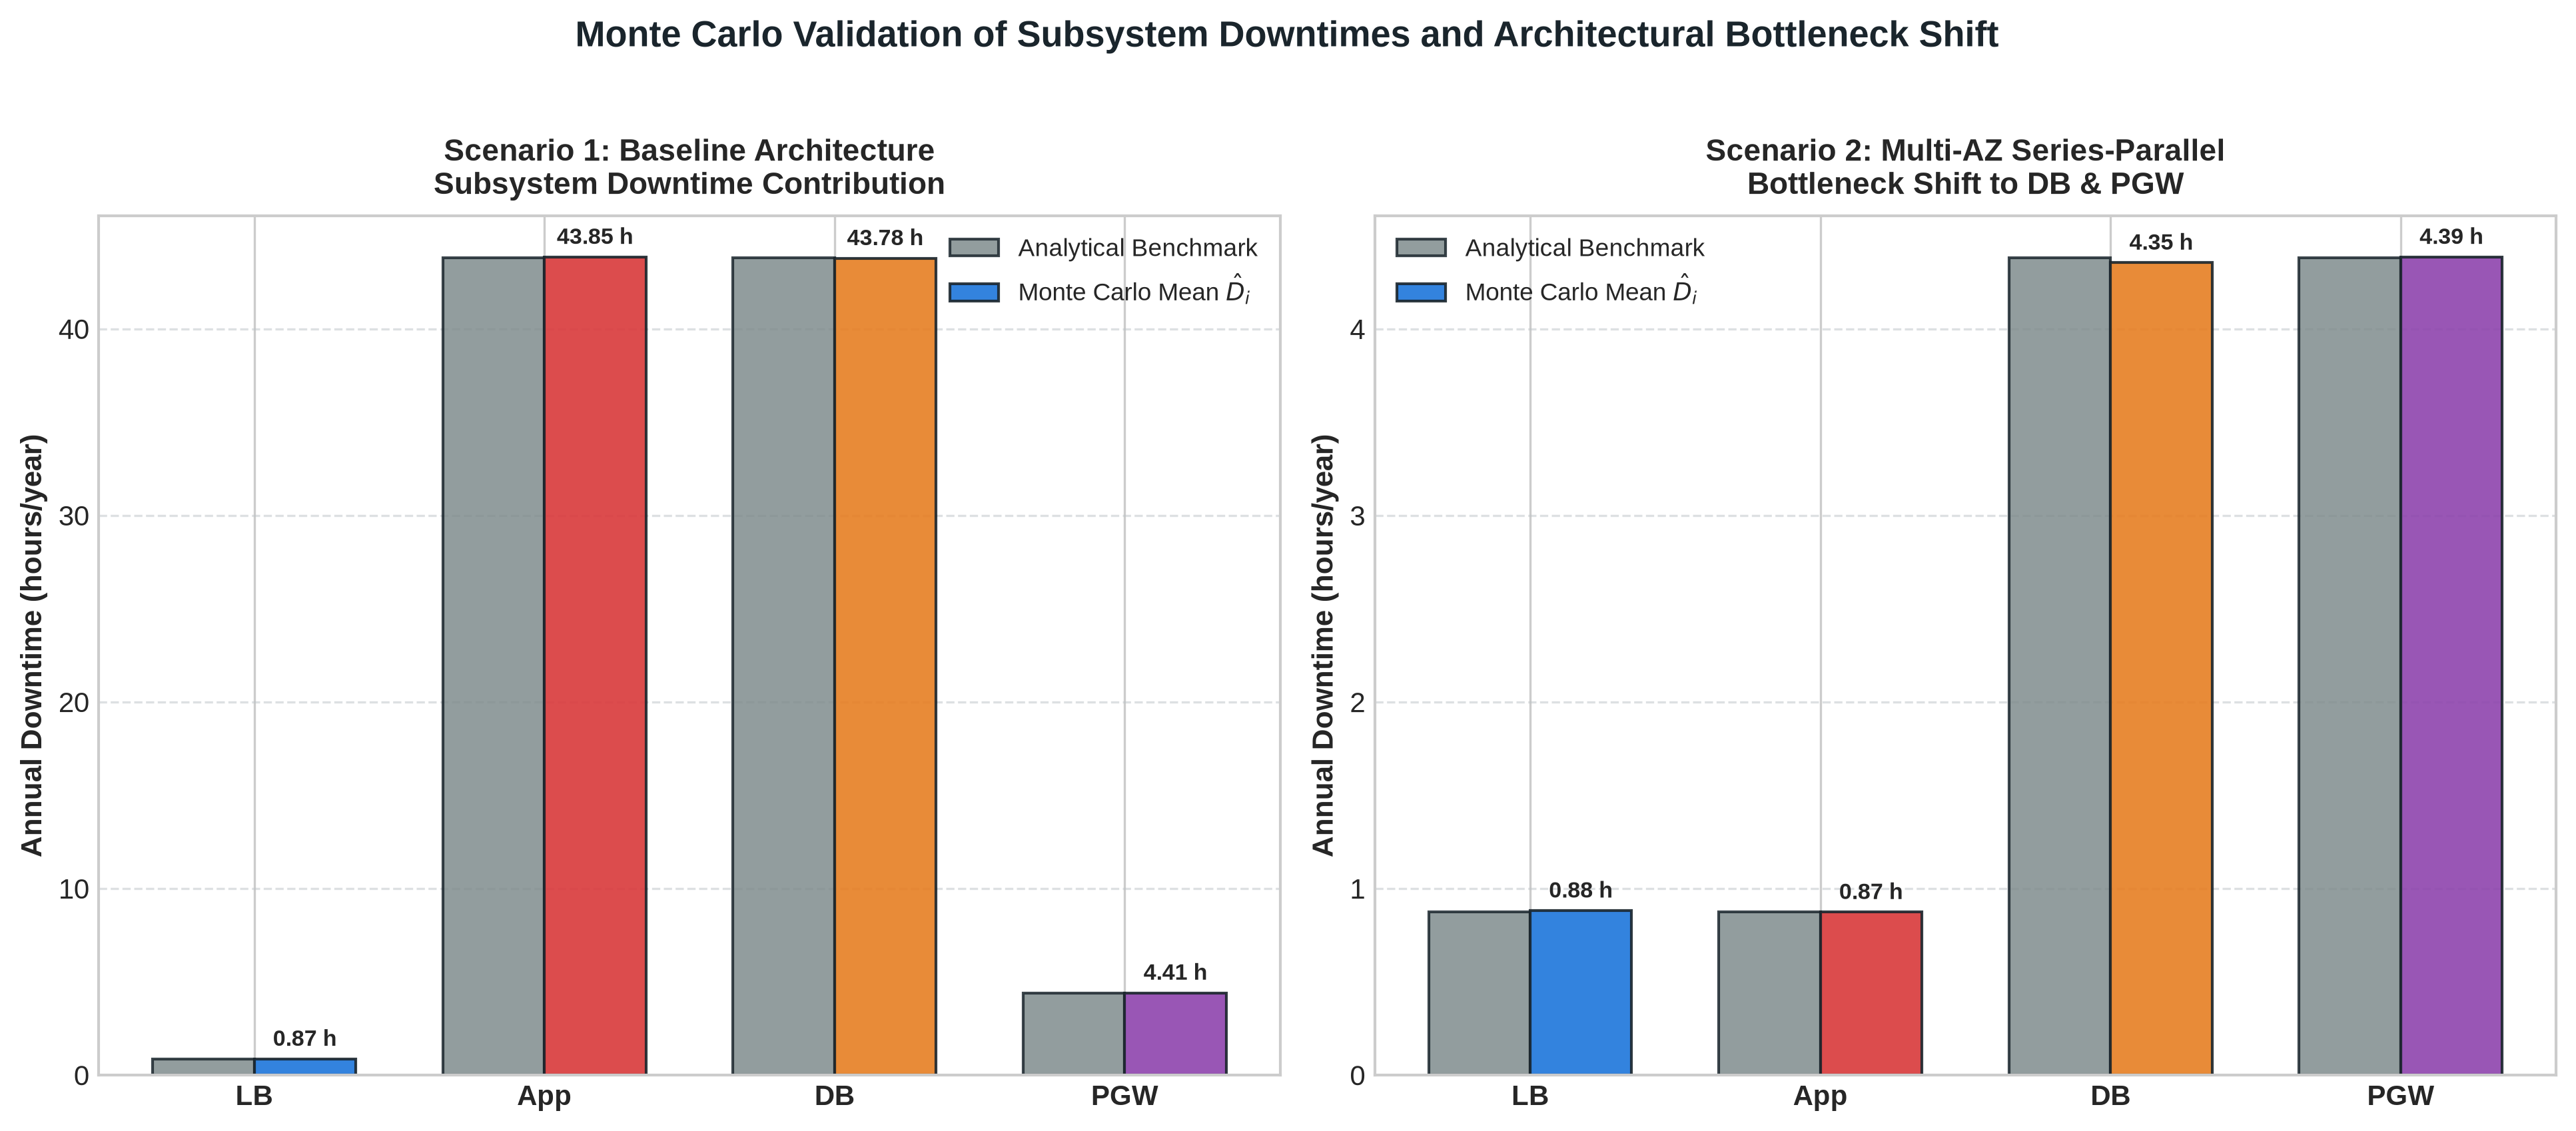

In [9]:
blocks = ['LB', 'App', 'DB', 'PGW']
subsystem_rows = []

# Analytical reference values
analytical_subs = {
    1: {'LB': 0.876, 'App': 43.800, 'DB': 43.800, 'PGW': 4.380},
    2: {'LB': 0.876, 'App': 0.876, 'DB': 4.380, 'PGW': 4.380},
    3: {'LB': 0.876, 'App': 0.876, 'DB': 4.380, 'PGW': 0.00219},
}

for s_id, res in all_sim_results.items():
    tot_sim_dt = res.metrics.mean_downtime_hours
    for b in blocks:
        arr = res.subsystem_downtimes[b]
        sim_mean = float(np.mean(arr))
        theo_val = analytical_subs[s_id][b]
        share_pct = (sim_mean / tot_sim_dt) * 100.0
        subsystem_rows.append({
            'Scenario': f'Scenario {s_id}',
            'Block': b,
            'Analytical D_i (h/yr)': theo_val,
            'Simulated D_hat_i (h/yr)': sim_mean,
            'Simulated Share (%)': share_pct,
            'Abs Difference (h)': abs(sim_mean - theo_val),
        })

df_sub_comparison = pd.DataFrame(subsystem_rows)
print('\nSIMULATED VS. ANALYTICAL SUBSYSTEM DOWNTIME (PARETO CROSS-VALIDATION)\n')
display(df_sub_comparison)

fig_sub = plot_simulation_subsystem_breakdown(all_sim_results, output_dir=figures_dir)
plt.show()

sub_img_path = figures_dir / 'monte_carlo_pareto_validation.png'
if sub_img_path.exists():
    display(Image(filename=str(sub_img_path), width=850))
